In [8]:
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np
import random
from datasets import load_dataset
import pandas as pd
from collections import Counter

random.seed(42)  # để chọn ảnh mẫu cố định, xem lại ra cùng kết quả

DATA = Path("..") / "data"          # ← lùi ra khỏi notebooks/ rồi vào data/
SEG_IMG = DATA / "kvasir-seg" / "images"
SEG_MASK = DATA / "kvasir-seg" / "masks"

## **Dataset Kvasir-SEG**

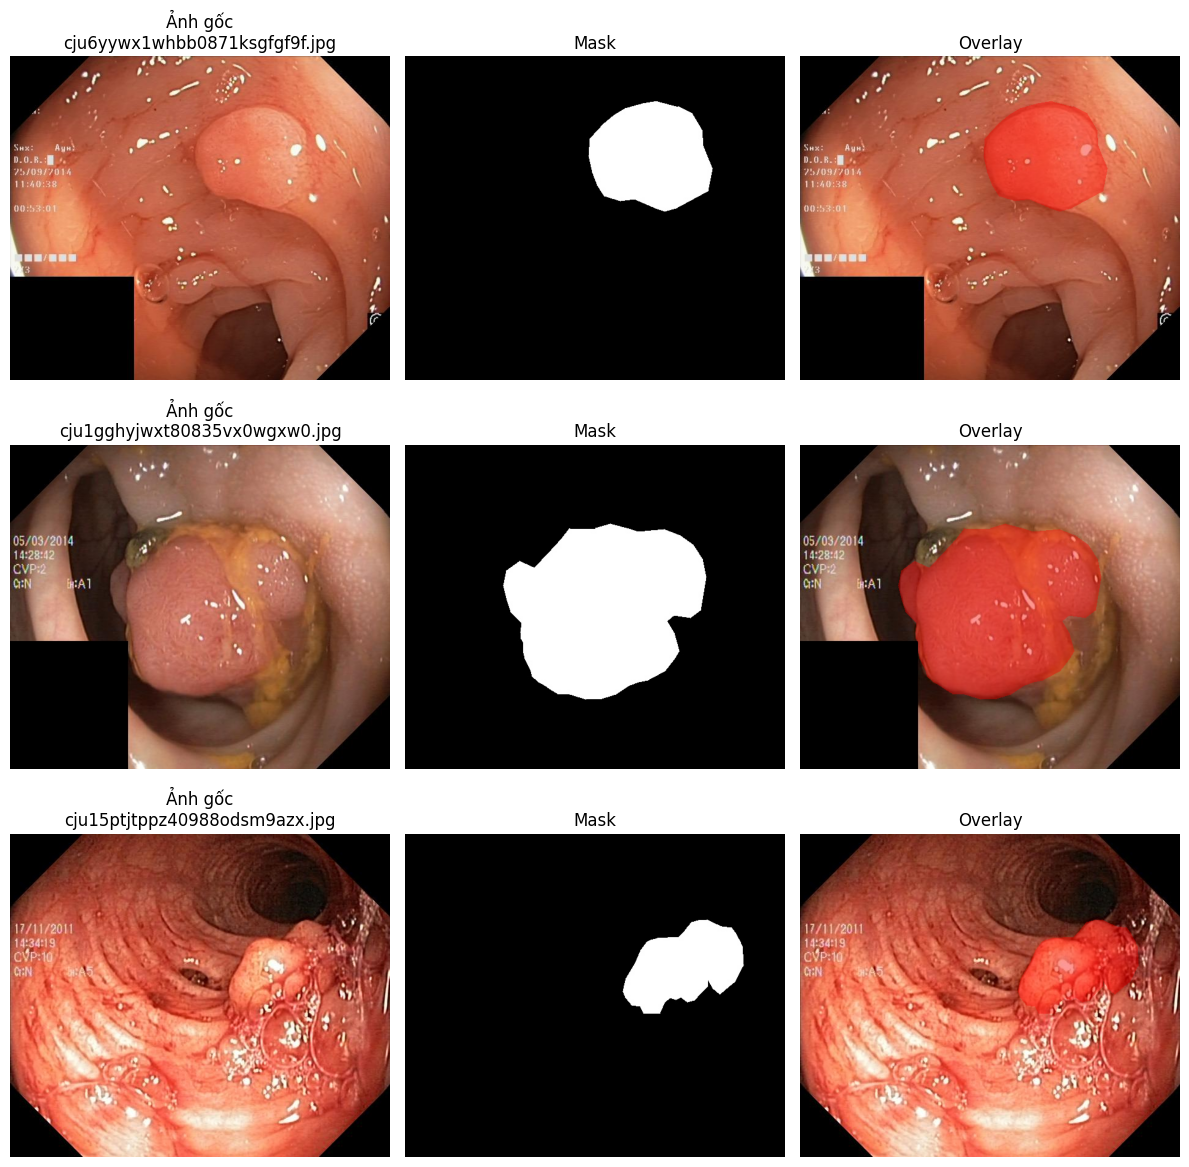

In [6]:
# Lấy 3 ảnh ngẫu nhiên
seg_files = sorted(SEG_IMG.glob("*.jpg"))
samples = random.sample(seg_files, 3)

fig, axes = plt.subplots(3, 3, figsize=(12, 12))
for row, img_path in enumerate(samples):
    mask_path = SEG_MASK / img_path.name  # mask cùng tên

    img = Image.open(img_path).convert("RGB")
    mask = Image.open(mask_path).convert("L")  # grayscale

    # Overlay: tô đỏ vùng mask lên ảnh gốc
    img_np = np.array(img)
    mask_np = np.array(mask)
    overlay = img_np.copy()
    overlay[mask_np > 127] = [255, 0, 0]  # vùng polyp → đỏ
    blended = (0.6 * img_np + 0.4 * overlay).astype(np.uint8)

    axes[row, 0].imshow(img);      axes[row, 0].set_title(f"Ảnh gốc\n{img_path.name}")
    axes[row, 1].imshow(mask, cmap="gray"); axes[row, 1].set_title("Mask")
    axes[row, 2].imshow(blended);  axes[row, 2].set_title("Overlay")
    for c in range(3):
        axes[row, c].axis("off")

plt.tight_layout()
plt.show()

## **Dataset Kvasir-v2**
- Data này bổ sung để giúp cho việc train model sẽ không sinh ra polyp ảo.

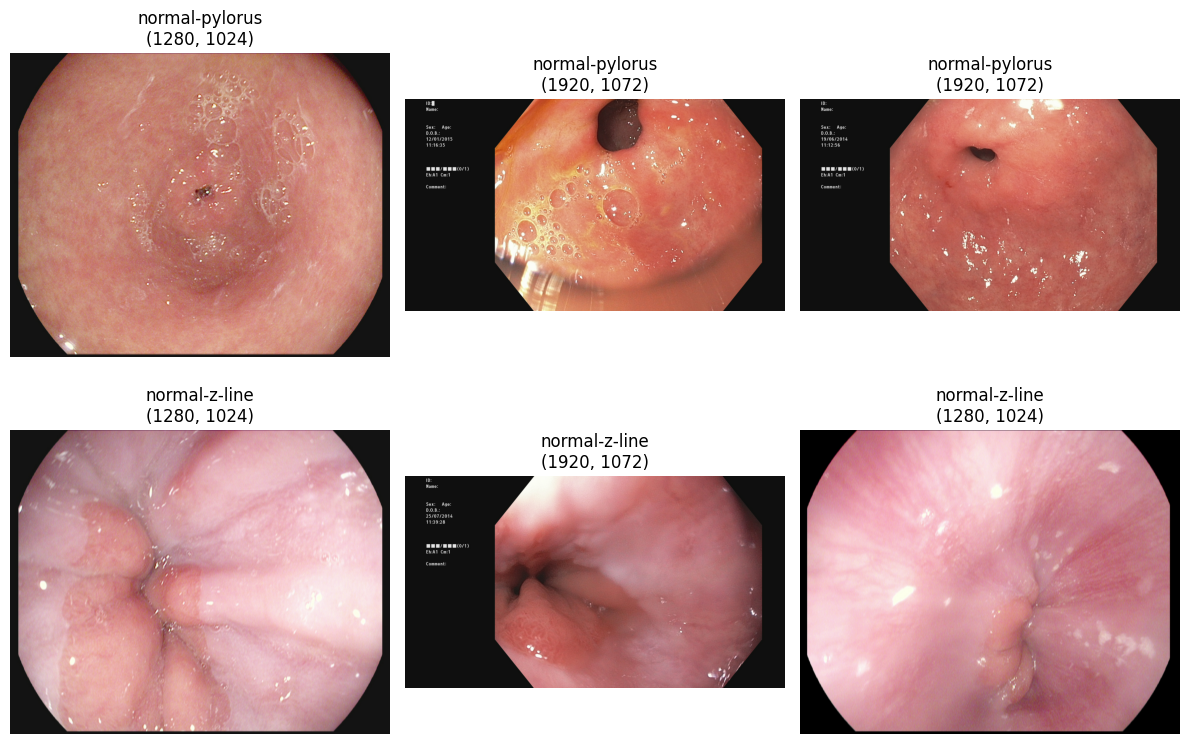

In [7]:
NORMAL_DIR = DATA / "kvasir-v2-normal"
classes = ["normal-pylorus", "normal-z-line"]

fig, axes = plt.subplots(len(classes), 3, figsize=(12, 8))
for row, cls in enumerate(classes):
    cls_files = sorted((NORMAL_DIR / cls).glob("*.jpg"))
    picks = random.sample(cls_files, 3)  # 3 ảnh mỗi class

    for col, img_path in enumerate(picks):
        img = Image.open(img_path).convert("RGB")
        axes[row, col].imshow(img)
        axes[row, col].set_title(f"{cls}\n{img.size}")  # kèm kích thước
        axes[row, col].axis("off")

plt.tight_layout()
plt.show()

## **Dataset Kvasir-VQA-x1**

In [15]:
ds = load_dataset("SimulaMet/Kvasir-VQA-x1")
print(ds)

train_df = pd.DataFrame(ds['train'])
test_df = pd.DataFrame(ds['test'])

print(f"\nTrain columns: {train_df.columns.tolist()}")
print(f"\nSample row:\n{train_df.iloc[0]}")

DatasetDict({
    train: Dataset({
        features: ['image', 'complexity', 'question', 'answer', 'original', 'question_class', 'img_id'],
        num_rows: 143594
    })
    test: Dataset({
        features: ['image', 'complexity', 'question', 'answer', 'original', 'question_class', 'img_id'],
        num_rows: 15955
    })
})

Train columns: ['image', 'complexity', 'question', 'answer', 'original', 'question_class', 'img_id']

Sample row:
image             https://huggingface.co/datasets/SimulaMet/Kvas...
complexity                                                        3
question          Are there any abnormalities, polyps, or anatom...
answer            Evidence of oesophagitis is present with no po...
original          [\n{\n"q": "Are there any abnormalities in the...
question_class    [abnormality_presence, polyp_type, landmark_pr...
img_id                                    clb0kvxvm90y4074yf50vf5nq
Name: 0, dtype: object


### 1. Tổng quan về số lượng

In [16]:
train_imgs = set(train_df['img_id'].unique())
test_imgs = set(test_df['img_id'].unique())
overlap_imgs = train_imgs & test_imgs

print("=" * 50)
print("TỔNG QUAN SỐ LƯỢNG")
print("=" * 50)
print(f"Train — QA pairs : {len(train_df):,}")
print(f"Train — Ảnh unique: {len(train_imgs):,}")
print(f"Test  — QA pairs : {len(test_df):,}")
print(f"Test  — Ảnh unique: {len(test_imgs):,}")
print(f"\nẢnh trùng (train ∩ test): {len(overlap_imgs):,}")
print(f"Tỷ lệ trùng / test imgs : {len(overlap_imgs)/len(test_imgs)*100:.1f}%")
print(f"Tỷ lệ trùng / tổng imgs : {len(overlap_imgs)/(len(train_imgs|test_imgs))*100:.1f}%")

TỔNG QUAN SỐ LƯỢNG
Train — QA pairs : 143,594
Train — Ảnh unique: 6,212
Test  — QA pairs : 15,955
Test  — Ảnh unique: 4,058

Ảnh trùng (train ∩ test): 3,821
Tỷ lệ trùng / test imgs : 94.2%
Tỷ lệ trùng / tổng imgs : 59.2%


Vấn đề:
- 3821 ảnh xuất hiện cả train lẫn test.
- Tỷ lệ trùng so với test: 94.2% => gần như toàn bộ ảnh test đã có trong train.

Hậu quả:
- Model đã thấy 94.2% ảnh test trong quá trình training.
- Metric trên test set bị chấm tốt tuyệt đối, khi đó không phản ánh khả năng khái quát hóa được trên ảnh mới. 

### 2. Phân bố Q&A trên mỗi ảnh


Train — QA pairs per ảnh:
  Mean   : 23.1
  Median : 26.0
  Min    : 1
  Max    : 50

Test — QA pairs per ảnh:
  Mean   : 3.9
  Median : 4.0
  Min    : 1
  Max    : 12


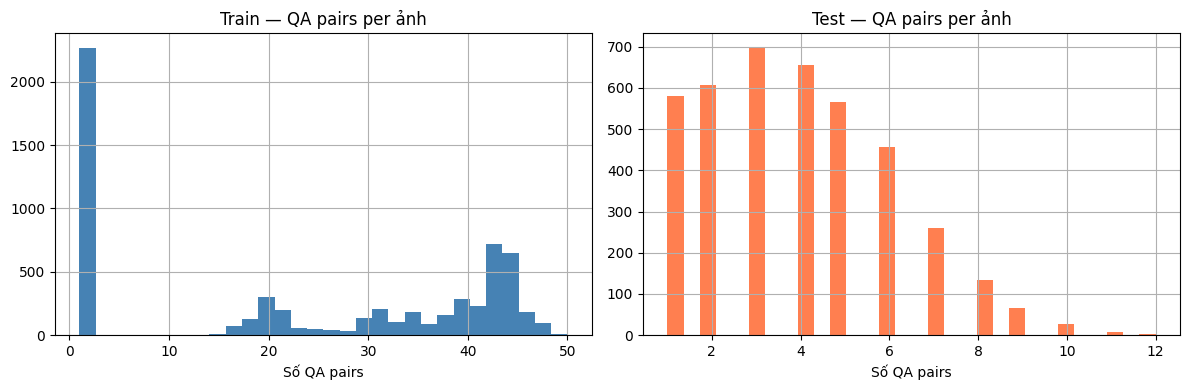

In [17]:
train_qa_per_img = train_df.groupby('img_id').size()
test_qa_per_img = test_df.groupby('img_id').size()

for name, series in [("Train", train_qa_per_img), ("Test", test_qa_per_img)]:
    print(f"\n{name} — QA pairs per ảnh:")
    print(f"  Mean   : {series.mean():.1f}")
    print(f"  Median : {series.median():.1f}")
    print(f"  Min    : {series.min()}")
    print(f"  Max    : {series.max()}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
train_qa_per_img.hist(bins=30, ax=axes[0], color='steelblue')
axes[0].set_title("Train — QA pairs per ảnh")
axes[0].set_xlabel("Số QA pairs")
test_qa_per_img.hist(bins=30, ax=axes[1], color='coral')
axes[1].set_title("Test — QA pairs per ảnh")
axes[1].set_xlabel("Số QA pairs")
plt.tight_layout()
plt.show()

### 3. Phân bố mức độ phức tạp của bộ Q&A


PHÂN BỐ COMPLEXITY LEVEL
                Train (%)  Test (%)
complexity_val                     
1                    34.4      34.4
2                    32.8      32.9
3                    32.8      32.6


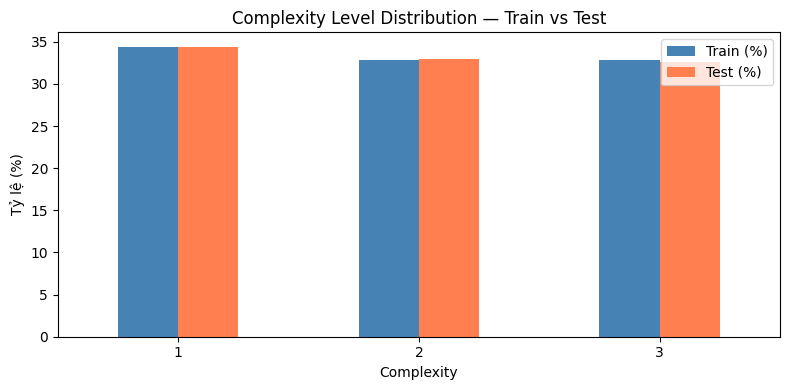

In [19]:
def get_complexity(df):
    col = df['question_type'] if 'question_type' in df.columns else df.get('complexity', None)
    # Tên cột thực tế sẽ hiện ra ở Cell 1 — điều chỉnh nếu cần
    return col

train_df['complexity_val'] = train_df['complexity'].apply(
    lambda x: x.tolist() if isinstance(x, np.ndarray) else x
)
test_df['complexity_val'] = test_df['complexity'].apply(
    lambda x: x.tolist() if isinstance(x, np.ndarray) else x
)

train_comp = train_df['complexity_val'].value_counts(normalize=True).sort_index() * 100
test_comp = test_df['complexity_val'].value_counts(normalize=True).sort_index() * 100

comp_summary = pd.DataFrame({
    'Train (%)': train_comp,
    'Test (%)': test_comp
}).round(1)
print("\nPHÂN BỐ COMPLEXITY LEVEL")
print(comp_summary.to_string())

comp_summary.plot(kind='bar', figsize=(8, 4), color=['steelblue', 'coral'])
plt.title("Complexity Level Distribution — Train vs Test")
plt.xlabel("Complexity")
plt.ylabel("Tỷ lệ (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

- Complexity level phân bố gần như hoàn hảo giữa train và test (chênh lệch tối đa 0.2%). Có thể tác giả đã stratify theo complexity khi tạo split gốc.

Lưu ý: khi gộp lại và split theo img_id, cần verify lại phân bố này — không đảm bảo tự nhiên đều như split gốc.

### 4. Phân bố class trong câu hỏi


QUESTION CLASS DISTRIBUTION
                       Train (%)  Test (%)
procedure_type              7.50      7.28
polyp_removal_status        7.47      7.31
box_artifact_presence       7.42      7.33
text_presence               7.42      7.76
instrument_count            6.69      6.98
finding_count               6.48      6.69
polyp_type                  6.33      6.20
polyp_size                  6.21      6.12
instrument_presence         5.98      5.81
instrument_location         5.97      6.05
polyp_count                 5.93      6.01
abnormality_location        5.93      6.01
abnormality_color           5.88      5.89
abnormality_presence        5.86      5.76
landmark_location           4.18      3.87
landmark_presence           3.78      4.00
finding_presence            0.79      0.75
landmark_color              0.17      0.17


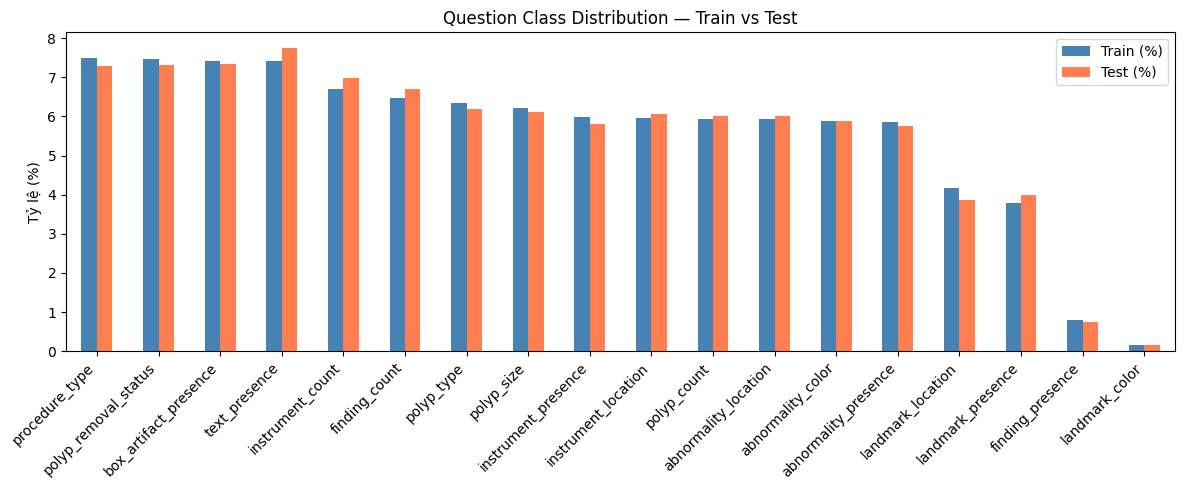

In [ ]:
def explode_class(df, col='question_class'):
    import numpy as np
    rows = []
    for val in df[col]:
        if isinstance(val, (list, np.ndarray)):
            for v in val:
                rows.append(str(v))
        else:
            rows.append(str(val))
    return pd.Series(rows)

train_classes = explode_class(train_df)
test_classes = explode_class(test_df)

train_class_pct = train_classes.value_counts(normalize=True) * 100
test_class_pct = test_classes.value_counts(normalize=True) * 100

class_summary = pd.DataFrame({
    'Train (%)': train_class_pct,
    'Test (%)': test_class_pct
}).fillna(0).round(2).sort_values('Train (%)', ascending=False)

print("\nQUESTION CLASS DISTRIBUTION")
print(class_summary.to_string())

class_summary.plot(kind='bar', figsize=(12, 5), color=['steelblue', 'coral'])
plt.title("Question Class Distribution — Train vs Test")
plt.ylabel("Tỷ lệ (%)")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

- Question class phân bố đều giữa train và test (chênh lệch < 0.5%) tác giả có thể đã stratify theo question_class khi tạo split gốc.

 Hai class hiếm cần chú ý khi split lại theo img_id:
   - finding_presence : ~0.77%
   - landmark_color   : ~0.17% 
=> Nếu split lại mà hai class này lệch > 5% → đổi seed và split lại.

### 5. Phân phối câu trả lời của tập train và test

In [21]:
for name, df in [("Train", train_df), ("Test", test_df)]:
    answers = df['answer'].str.lower().str.strip()
    total = len(answers)
    yes_count = (answers == 'yes').sum()
    no_count = (answers == 'no').sum()
    print(f"\n{name} — Answer distribution:")
    print(f"  Yes : {yes_count:,} ({yes_count/total*100:.1f}%)")
    print(f"  No  : {no_count:,} ({no_count/total*100:.1f}%)")
    print(f"  Khác: {total - yes_count - no_count:,} ({(total-yes_count-no_count)/total*100:.1f}%)")
    print(f"\n  Top 15 answers:")
    print(df['answer'].value_counts().head(15).to_string())


Train — Answer distribution:
  Yes : 0 (0.0%)
  No  : 0 (0.0%)
  Khác: 143,594 (100.0%)

  Top 15 answers:
answer
evidence of colonoscopy procedure            1719
No residual polyp tissue identified          1047
No instruments observed                       913
No anatomical landmarks identified            801
No evidence of box artifacts observed         795
No surgical instruments observed              739
one surgical instrument present               730
No polyps observed                            706
one abnormal finding present                  696
No surgical instruments identified            676
evidence of green and black box artifacts     640
No polyps identified                          637
evidence of colonic polyp                     635
evidence of colonoscopic examination          615
evidence of esophageal inflammation           594

Test — Answer distribution:
  Yes : 0 (0.0%)
  No  : 0 (0.0%)
  Khác: 15,955 (100.0%)

  Top 15 answers:
answer
evidence of colonoscop

- Câu trả lời có dạng template cố định ("No X observed", "evidence of X") => BLIP có khả năng học pattern tốt, metric ROUGE-L có thể cao hơn dataset free-form thông thường

### 6. Hiển thị 1 ảnh và bộ QA với ảnh tương ứng.

Resolving data files:   0%|          | 0/31 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/31 [00:00<?, ?it/s]

Loading dataset shards:   0%|          | 0/30 [00:00<?, ?it/s]

Loaded 6500 ảnh

Img ID: clb0kvxvm90y4074yf50vf5nq
Tổng QA pairs của ảnh này (trong train): 41

5 bộ QA:
  Q: Are there any abnormalities, polyps, or anatomical landmarks visible in the image?
  A: Evidence of oesophagitis is present with no polyps identified and the z-line is visible.

  Q: Are there any remaining polyps and is there a green/black box artefact present?
  A: No residual polyps identified and no green or black box artefact observed

  Q: In which regions of the image is the abnormality observed and what procedure was performed?
  A: Abnormalities are seen scattered across multiple regions including central and upper areas, and the image is from a gastroscopy procedure.

  Q: How many polyps and instruments are visible, and are there any abnormalities such as oesophagitis present in the image?
  A: No polyps or instruments are visible, and there is evidence of oesophagitis.

  Q: What type of polyp is present, what procedure was used to obtain the image, and is there a g

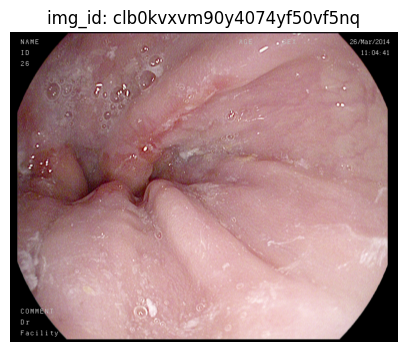

In [23]:
img_ds = load_dataset("SimulaMet-HOST/Kvasir-VQA", split="raw")
img_lookup = {row['img_id']: row['image'] for row in img_ds}
print(f"Loaded {len(img_lookup)} ảnh")

# Chọn ảnh có >= 5 QA pairs trong train
eligible = train_df.groupby('img_id').filter(lambda x: len(x) >= 5)
sample_img_id = eligible['img_id'].iloc[0]
sample_rows = train_df[train_df['img_id'] == sample_img_id].head(5)

print(f"\nImg ID: {sample_img_id}")
print(f"Tổng QA pairs của ảnh này (trong train): {len(train_df[train_df['img_id'] == sample_img_id])}")
print("\n5 bộ QA:")
for i, row in sample_rows.iterrows():
    print(f"  Q: {row['question']}")
    print(f"  A: {row['answer']}")
    print()

# Hiển thị ảnh
if sample_img_id in img_lookup:
    img = img_lookup[sample_img_id]
    plt.figure(figsize=(5, 5))
    plt.imshow(img)
    plt.title(f"img_id: {sample_img_id}")
    plt.axis('off')
    plt.show()
else:
    print(f"Không tìm thấy img_id '{sample_img_id}' trong image dataset")
    print(f"Sample img_ids có trong image dataset: {list(img_lookup.keys())[:5]}")